In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.gridspec as gridspec
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import scipy.stats as stats
import shutil
import warnings
warnings.filterwarnings('ignore')

In [2]:
'''Google Drive'''
from google.colab import drive
from google.colab import files
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
'''Set plot features'''

import matplotlib.font_manager as fm

plt.style.use("default")

plt.rcParams.update({
    # Font
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 14,

    # Axes
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "axes.linewidth": 1.2,

    # Ticks
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 6,
    "ytick.major.size": 6,

    # Lines
    "lines.linewidth": 2,

    # Legend
    "legend.frameon": False,
    "legend.fontsize": 12,

    # Figure
    #"figure.figsize": (6,4),
    "figure.dpi": 120,

    # Save quality
    "savefig.dpi": 300,
    "savefig.bbox": "tight"
})

def nice_axes(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


In [4]:
'''Load data and create full table'''

shutil.copy('/content/drive/MyDrive/Football Projects/games.csv', './games.csv')
shutil.copy('/content/drive/MyDrive/Football Projects/events.csv', './events.csv')

games = pd.read_csv('games.csv')
events = pd.read_csv('events.csv')

# Total goals
games['total_goals'] = games['home_goals'] + games['away_goals']

# Red cards
rc = events[events['type'] == 'red_card']

games['red_cards'] = (rc.groupby('game_id').size()
                        .reindex(games['game_id']).fillna(0).astype(int).values)

games['has_red_card'] = (games['red_cards'] > 0).astype(int)

# Earliest red card minute per game (.min() not .sum())
games['red_card_minute'] = (rc.groupby('game_id')['minute'].min()
                              .reindex(games['game_id']).values)

# Home and away red card counts
games['home_rc'] = (rc[rc['side'] == 'home'].groupby('game_id').size()
                      .reindex(games['game_id']).fillna(0).astype(int).values)
games['away_rc'] = (rc[rc['side'] == 'away'].groupby('game_id').size()
                      .reindex(games['game_id']).fillna(0).astype(int).values)

# RC side label for games that have exactly one red card side
games['rc_side'] = 'none'
games.loc[(games['home_rc'] > 0) & (games['away_rc'] == 0), 'rc_side'] = 'home'
games.loc[(games['away_rc'] > 0) & (games['home_rc'] == 0), 'rc_side'] = 'away'
games.loc[(games['home_rc'] > 0) & (games['away_rc'] > 0),  'rc_side'] = 'both'

# Red card timing phase
red_games = games[games['has_red_card'] == 1].copy()
games['rc_phase'] = pd.cut(
    games['red_card_minute'],
    bins=[0, 45, 75, 90],
    labels=['Early (1–45)', 'Mid (46–75)', 'Late (76–90)']
)

# Top-5 league flag
TOP5 = ['Premier League', 'Primera', '1. Bundesliga', 'Serie A', 'Ligue 1']
games['top5'] = games['competition'].apply(
    lambda x: 'Top 5' if any(t in x for t in TOP5) else 'Other'
)

games['date'] = pd.to_datetime(games['date'])

print(f"Total games       : {len(games):,}")
print(f"Games with RC     : {games['has_red_card'].sum():,} "
      f"({100*games['has_red_card'].mean():.1f}%)")
print(f"Total red cards   : {int(games['red_cards'].sum())}")
print(f"Competitions      : {games['competition'].nunique()}")
print(f"Date range        : {games['date'].min().date()} → {games['date'].max().date()}")
print()
print(games[['game_id', 'date', 'competition','total_goals', 'has_red_card', 'red_cards',
             'red_card_minute','rc_side','rc_phase','top5']].head(1000))

Total games       : 20,370
Games with RC     : 3,273 (16.1%)
Total red cards   : 3731
Competitions      : 10
Date range        : 2018-07-27 → 2023-06-04


In [ ]:
# summary statistics
print("Red card count distribution:")
print(games['red_cards'].value_counts().sort_index())
print()
total_overall_goals = games['total_goals'].sum()
total_red_cards = games['red_cards'].sum()
print(f"Total red cards across all games: {int(total_red_cards):,}")
print(f"Total goals across all games: {int(total_overall_goals):,}")
print()
print(f"Total goal distribution:")
print(games['total_goals'].describe().round(3))
print()
print("Mean goals by red-card presence:")
print(games.groupby('has_red_card')['total_goals'].agg(['mean','median','std','count']).rename(index={0:'No RC', 1:'RC'}).round(3))
print()
print("Mean goals by red card count:")
print(games.groupby('red_cards')['total_goals'].agg(['mean', 'median', 'std', 'count']).round(3))

Red card count distribution:
red_cards
0    17097
1     2871
2      356
3       38
4        6
5        2
Name: count, dtype: int64

Total red cards across all games: 3,731
Total goals across all games: 54,019

Total goal distribution:
count    20370.000
mean         2.652
std          1.640
min          0.000
25%          1.000
50%          2.000
75%          4.000
max         11.000
Name: total_goals, dtype: float64

Mean goals by red-card presence:
               mean  median    std  count
has_red_card                             
No RC         2.644     2.0  1.639  17097
RC            2.695     3.0  1.645   3273

Mean goals by red card count:
            mean  median    std  count
red_cards                             
0          2.644     2.0  1.639  17097
1          2.686     3.0  1.640   2871
2          2.699     3.0  1.637    356
3          3.158     3.0  1.994     38
4          3.500     3.5  1.643      6
5          3.000     3.0  2.828      2


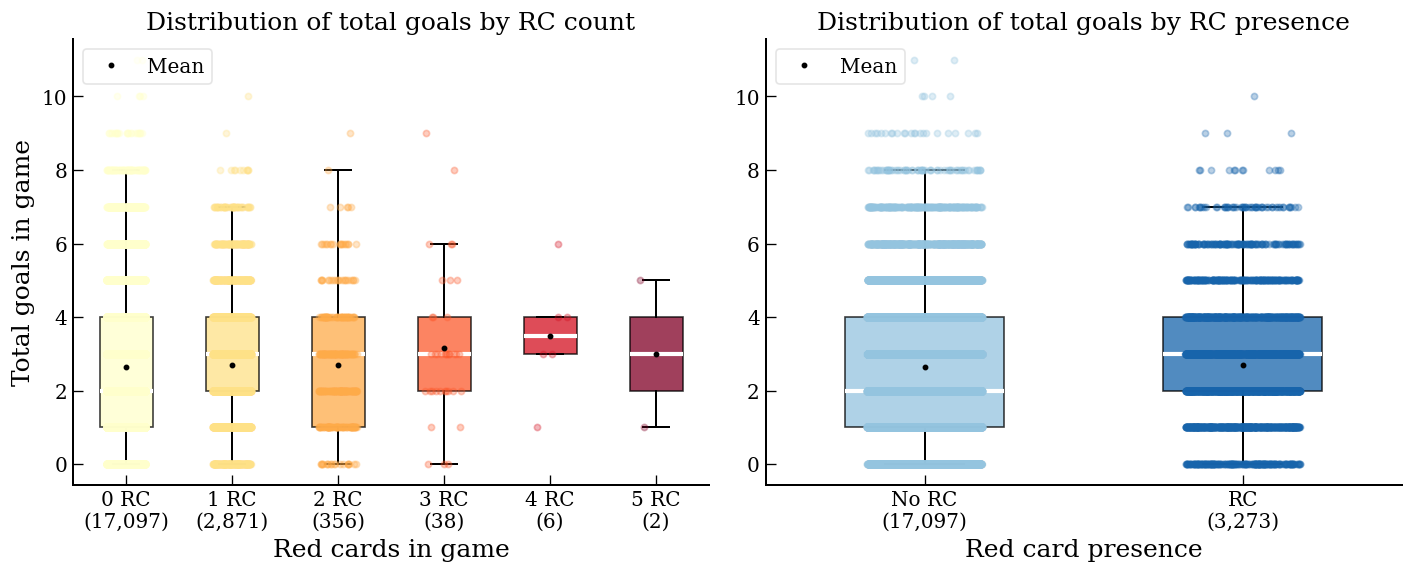

Goals include goals scored before red card happened - must consider timing of red card.


In [6]:
"""Figure 1: Box Plots for Mean Goals vs RC Count and RC Presence"""

rng       = np.random.default_rng()
rc_counts = sorted(games['red_cards'].unique())
cmap      = plt.colormaps['YlOrRd'].resampled(max(len(rc_counts), 3))
PALETTE   = {n: cmap(i) for i, n in enumerate(rc_counts)}
grouped   = [games[games['red_cards'] == n]['total_goals'].values for n in rc_counts]
labels    = [f"{n} RC\n({len(g):,})" for n, g in zip(rc_counts, grouped)]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

''' Panel 1: Box plot (RC Count) '''
ax = axes[0]
bp = ax.boxplot(grouped, patch_artist=True, widths=0.5,
                medianprops=dict(color='white', linewidth=2.5),
                whiskerprops=dict(linewidth=1.2),
                capprops=dict(linewidth=1.2),
                flierprops=dict(marker=''))
for patch, n in zip(bp['boxes'], rc_counts):
    patch.set_facecolor(PALETTE[n])
    patch.set_alpha(0.75)

for i, (n, vals) in enumerate(zip(rc_counts, grouped), start=1):
    jitter = rng.uniform(-0.18, 0.18, size=len(vals))
    ax.scatter(i + jitter, vals, color=PALETTE[n], alpha=0.3, s=14, zorder=3)

means = [v.mean() for v in grouped]
ax.plot(range(1, len(rc_counts)+1), means, '.', color='black',
        markersize=5, zorder=4, label='Mean')
ax.set_xticks(range(1, len(rc_counts)+1))
ax.set_xticklabels(labels)
ax.set_xlabel('Red cards in game')
ax.set_ylabel('Total goals in game')
ax.set_title('Distribution of total goals by RC count')
nice_axes(ax)
ax.legend(loc="upper left", frameon=True, framealpha=0.5)

''' Panel 2: Box Plot (RC Presence) '''
ax = axes[1]

# Prepare data for No RC vs RC
has_rc_categories = sorted(games['has_red_card'].unique())
grouped_has_rc = [games[games['has_red_card'] == cat]['total_goals'].values for cat in has_rc_categories]
labels_has_rc = [f"No RC\n({len(grouped_has_rc[0]):,})", f"RC\n({len(grouped_has_rc[1]):,})"]

# Panel 2 Colourmap
cmap_full_blues = plt.colormaps['Blues']
PALETTE_PANEL2 = {
    has_rc_categories[0]: cmap_full_blues(0.4),  # A darker blue for 'No RC'
    has_rc_categories[1]: cmap_full_blues(0.8)   # A bolder blue for 'RC'
}

bp2 = ax.boxplot(grouped_has_rc, patch_artist=True, widths=0.5,
                 medianprops=dict(color='white', linewidth=2.5),
                 whiskerprops=dict(linewidth=1.2),
                 capprops=dict(linewidth=1.2),
                 flierprops=dict(marker=''))

for patch, n in zip(bp2['boxes'], has_rc_categories):
    patch.set_facecolor(PALETTE_PANEL2[n])
    patch.set_alpha(0.75)

for i, (n, vals) in enumerate(zip(has_rc_categories, grouped_has_rc), start=1):
    jitter = rng.uniform(-0.18, 0.18, size=len(vals))
    ax.scatter(i + jitter, vals, color=PALETTE_PANEL2[n], alpha=0.3, s=14, zorder=3)

means_has_rc = [v.mean() for v in grouped_has_rc]
ax.plot(range(1, len(has_rc_categories)+1), means_has_rc, '.', color='black',
        markersize=5, zorder=4, label='Mean')

ax.set_xticks(range(1, len(has_rc_categories)+1))
ax.set_xticklabels(labels_has_rc)
ax.set_xlabel('Red card presence')
#ax.set_ylabel('Total goals in game')
ax.set_title('Distribution of total goals by RC presence')
ax.legend(loc="upper left", frameon=True, framealpha=0.5)

plt.tight_layout()
nice_axes(ax)
plt.show()

print("Goals include goals scored before red card happened - must consider timing of red card.")

In [7]:
# Mann-Whitney U test
no_rc_goals = games[games['has_red_card'] == 0]['total_goals']
rc_goals    = games[games['has_red_card'] == 1]['total_goals']

u_stat, p_mw = stats.mannwhitneyu(rc_goals, no_rc_goals, alternative='two-sided')
cohen_d = (rc_goals.mean() - no_rc_goals.mean()) / games['total_goals'].std()

print("Baseline statistical test (Mann-Whitney U):")
print(f"  No RC  — mean: {no_rc_goals.mean():.3f}, median: {no_rc_goals.median():.1f}")
print(f"  RC     — mean: {rc_goals.mean():.3f},    median: {rc_goals.median():.1f}")
print(f"  Raw difference in means: {rc_goals.mean() - no_rc_goals.mean():+.3f}")
print(f"  U={u_stat:.0f}, p={p_mw:.4f}")
print(f"  Cohen's d (effect size): {cohen_d:.4f}")
print(f"  Interpretation: {'Significant at p<0.05' if p_mw < 0.05 else 'Not significant at p<0.05'}")

Baseline statistical test (Mann-Whitney U):
  No RC  — mean: 2.644, median: 2.0
  RC     — mean: 2.695,    median: 3.0
  Raw difference in means: +0.051
  U=28436454, p=0.1309
  Cohen's d (effect size): 0.0311
  Interpretation: Not significant at p<0.05


In [8]:
'''First refinement: RC Timing'''

# Summarise data for each RC phase
bins = [0, 45, 75, 90]
labels = ["Early", "Mid", "Late"]

red_games["minute_bin"] = pd.cut(
    red_games["red_card_minute"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

bin_summary = red_games.groupby("minute_bin")["total_goals"].agg(["mean", "count", "std"]).reset_index()
bin_summary["se"] = bin_summary["std"] / np.sqrt(bin_summary["count"])

print(bin_summary)

  minute_bin      mean  count       std        se
0      Early  2.817016    858  1.636183  0.055858
1        Mid  2.714027   1105  1.662576  0.050015
2       Late  2.598473   1310  1.630214  0.045041


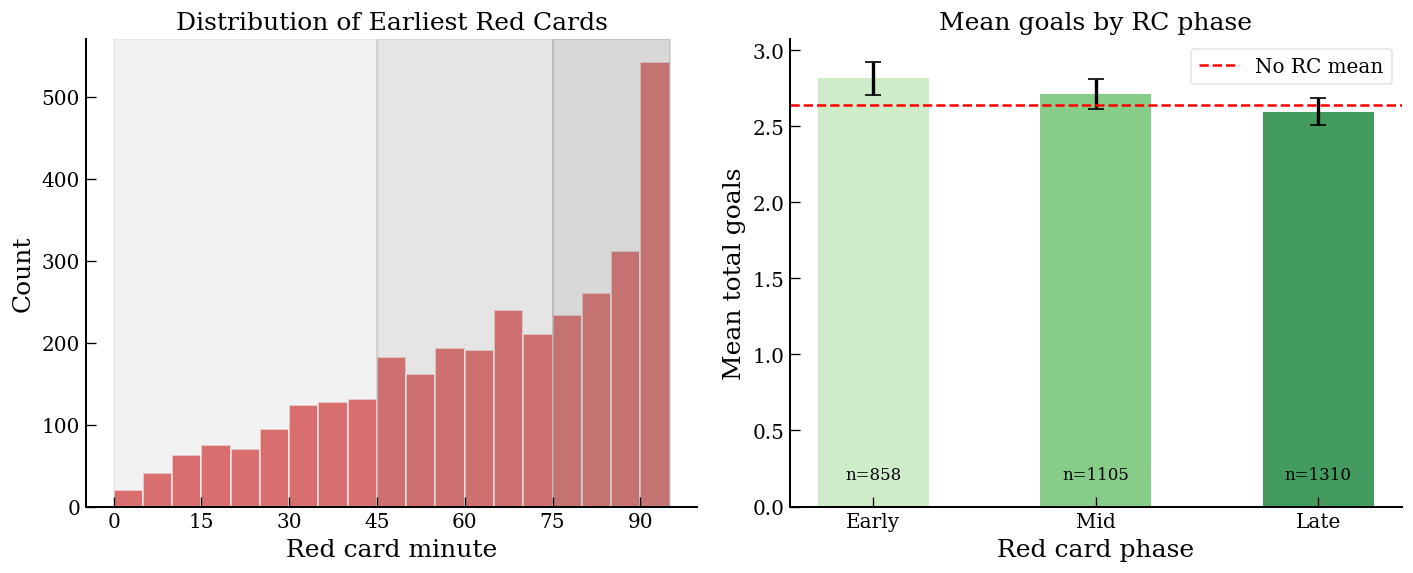

In [10]:
"""Figure 2: Timing effect (Combined Plot)"""

# Create a single figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# First Panel: RC minute histogram
ax0 = axes[0]
ax0.hist(red_games['red_card_minute'], bins=np.arange(0, 96, 5),
         color='#DD4949', alpha=0.8, edgecolor='white')

# Shade the early, mid, and late phases
ax0.axvspan(0, 45, color='gray', alpha=0.1, label='Early (0-45 min)')
ax0.axvspan(45, 75, color='gray', alpha=0.2, label='Mid (46-75 min)')
ax0.axvspan(75, 95, color='gray', alpha=0.3, label='Late (76-90 min)') # Extended to 95 to cover the last bin

ax0.set_xlabel('Red card minute')
ax0.set_ylabel('Count')
ax0.set_title('Distribution of Earliest Red Cards')
#ax0.legend(loc="upper left", frameon=True, framealpha=0.5)
ax0.set_xticks(np.arange(0, 91, 15)) # Set x-axis ticks
ax0.set_xticklabels(['0', '15', '30', '45', '60', '75', '90']) # Set custom labels
nice_axes(ax0)

# Second Panel: Mean goals by RC phase (using bins)
ax1 = axes[1]

no_rc_mean = games[games['has_red_card'] == 0]['total_goals'].mean()  # Mean goals scored in games with no RC

# Use bin_summary data for plotting
plot_labels = bin_summary['minute_bin']
plot_means = bin_summary['mean']
plot_errors = 1.96 * bin_summary['se'] # 95% CI
plot_counts = bin_summary['count']

# Changed colormap to 'Greens' for better distinction and adjusted colors for labels
phase_cmap  = plt.colormaps['Greens']
phase_cols  = [phase_cmap(0.25), phase_cmap(0.5), phase_cmap(0.75)] # Manually selected shades

bars1 = ax1.bar(plot_labels, plot_means,
                yerr=plot_errors, capsize=5,
                color=phase_cols, alpha=0.85, width=0.5)
ax1.axhline(no_rc_mean, color='red', linewidth=1.5, linestyle='--', label=f'No RC mean')
for bar, n in zip(bars1, plot_counts):
    ax1.text(bar.get_x() + bar.get_width()/2,
             0.15, f'n={n}', ha='center', va='bottom', fontsize=10, color='black') # Adjusted y-position and fontsize
ax1.set_xlabel('Red card phase')
ax1.set_ylabel('Mean total goals')
ax1.set_title('Mean goals by RC phase')
ax1.legend(frameon=True, framealpha=0.5)
nice_axes(ax1)
plt.tight_layout()
plt.show()

In [11]:
'''Second refinement: home or away red card'''

# Build home / away side dataframe
rows = []
for _, g in games.iterrows():
    rows.append({'goals_scored': g.home_goals, 'goals_conceded': g.away_goals,
                 'side': 'home', 'own_rc': int(g.home_rc > 0),
                 'opp_rc': int(g.away_rc > 0), 'total_goals': g.total_goals})
    rows.append({'goals_scored': g.away_goals, 'goals_conceded': g.home_goals,
                 'side': 'away', 'own_rc': int(g.away_rc > 0),
                 'opp_rc': int(g.home_rc > 0), 'total_goals': g.total_goals})
side_df = pd.DataFrame(rows)

print("Mean goals scored — own red card effect:")
print(side_df.groupby(['side','own_rc'])['goals_scored']
      .mean().unstack('own_rc')
      .rename(columns={0:'No own RC', 1:'Own RC'}).round(3))
print()
print("Mean goals scored — opponent red card effect:")
print(side_df.groupby(['side','opp_rc'])['goals_scored']
      .mean().unstack('opp_rc')
      .rename(columns={0:'No opp RC', 1:'Opp RC'}).round(3))
print()
print("Mean total goals by RC side:")
print(games.groupby('rc_side')['total_goals']
      .agg(['mean','std','count']).round(3))

Mean goals scored — own red card effect:
own_rc  No own RC  Own RC
side                     
away        1.226   0.906
home        1.486   1.113

Mean goals scored — opponent red card effect:
opp_rc  No opp RC  Opp RC
side                     
away        1.161   1.603
home        1.425   1.757

Mean total goals by RC side:
          mean    std  count
rc_side                     
away     2.675  1.618   1704
both     2.582  1.604    251
home     2.742  1.686   1318
none     2.644  1.639  17097


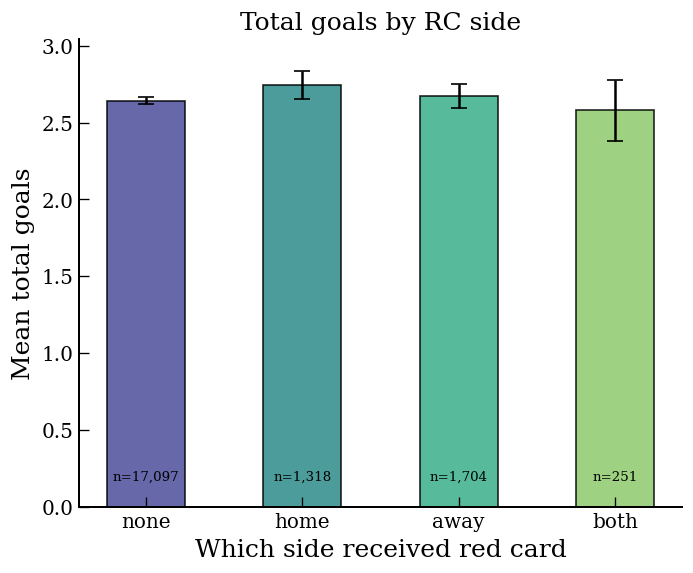

In [12]:
'''Figure 3: Total Goals by RC Side'''

fig, ax = plt.subplots(figsize=(6, 5))

rc_side_order = ['none', 'home', 'away', 'both']
rc_side_data  = games.groupby('rc_side')['total_goals'].agg(['mean', 'sem', 'count'])
rc_side_data  = rc_side_data.reindex([s for s in rc_side_order
                                      if s in rc_side_data.index])

rc_side_cols = ['#4B4E9B', '#2E8B8B', '#3AAF8A', '#8DC96B']

bars = ax.bar(rc_side_data.index, rc_side_data['mean'],
              yerr=1.96 * rc_side_data['sem'], capsize=5,
              color=rc_side_cols, alpha=0.85, width=0.5,
              edgecolor='black',  # Added black edge color
              error_kw=dict(linewidth=1.5))

for bar, (_, row) in zip(bars, rc_side_data.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2,
            0.15, f'n={int(row["count"]):,}', # Increased y-offset from 0.05 to 0.15
            ha='center', va='bottom', fontsize=8, color='black')

ax.set_xlabel('Which side received red card')
ax.set_ylabel('Mean total goals')
ax.set_title('Total goals by RC side')
ax.set_ylim(0, rc_side_data['mean'].max() + 0.3)
nice_axes(ax)

plt.tight_layout()
plt.show()

### Consider time of goal scored and measure goal RATE

In [ ]:
'''Extract pre- and post-RC features'''

games['date'] = pd.to_datetime(games['date'])
goals = events[events['type'] == 'goal'].copy()
rc    = events[events['type'] == 'red_card'].copy()

# Per-game red card features
rc_agg = rc.groupby('game_id').agg(
    red_cards       = ('type',   'count'),
    first_rc_minute = ('minute', 'min'),
    home_rc         = ('side',   lambda x: (x == 'home').sum()),
    away_rc         = ('side',   lambda x: (x == 'away').sum()),
).reset_index()


games = games.drop(columns=['red_cards', 'home_rc', 'away_rc', 'first_rc_minute'], errors='ignore')

games = games.merge(rc_agg, on='game_id', how='left')
games['red_cards']       = games['red_cards'].fillna(0).astype(int)
games['home_rc']         = games['home_rc'].fillna(0).astype(int)
games['away_rc']         = games['away_rc'].fillna(0).astype(int)
games['has_red_card']    = (games['red_cards'] > 0).astype(int)
# first_rc_minute remains NaN for no-RC games — intentional

# Split goals into before-RC and after-RC per game
# Merge goal events with first RC minute
goals = goals.merge(games[['game_id', 'first_rc_minute', 'has_red_card']],on='game_id', how='left')

# A goal is 'after RC' if it occurs at or after the first RC minute
# For no-RC games, all goals are 'before' (first_rc_minute is NaN)
goals['after_rc'] = (goals['has_red_card'] == 1) & (goals['minute'] >= goals['first_rc_minute'])

print(f"Goals before/no RC : {(~goals['after_rc']).sum():,}")
print(f"Goals after RC     : {goals['after_rc'].sum():,}")
print()

# Aggregate pre/post goal counts back to game level
def goals_split(side, after):
    """Count goals for a given side and before/after flag."""
    return (
        goals[(goals['side'] == side) & (goals['after_rc'] == after)]
        .groupby('game_id').size()
        .reindex(games['game_id']).fillna(0).astype(int).values
    )

games['home_goals_before_rc'] = goals_split('home', False)
games['away_goals_before_rc'] = goals_split('away', False)
games['home_goals_after_rc']  = goals_split('home', True)
games['away_goals_after_rc']  = goals_split('away', True)

games['total_goals_before_rc'] = games['home_goals_before_rc'] + games['away_goals_before_rc']
games['total_goals_after_rc']  = games['home_goals_after_rc']  + games['away_goals_after_rc']
games['total_goals']           = games['total_goals_before_rc'] + games['total_goals_after_rc']

# Minutes available in each period
# Used as exposure offset in the Poisson GLM
games['minutes_before_rc'] = games['first_rc_minute'].fillna(90).clip(upper=90)
games['minutes_after_rc']  = (90 - games['first_rc_minute']).clip(lower=0).fillna(0)
games['rc_side'] = 'none'
games.loc[(games['home_rc'] > 0) & (games['away_rc'] == 0), 'rc_side'] = 'home'
games.loc[(games['away_rc'] > 0) & (games['home_rc'] == 0), 'rc_side'] = 'away'
games.loc[(games['home_rc'] > 0) & (games['away_rc'] > 0),  'rc_side'] = 'both'

games['rc_phase'] = pd.cut(
    games['first_rc_minute'],
    bins=[0, 45, 75, 90],
    labels=['Early (1–45)', 'Mid (46–75)', 'Late (76–90)']
)

# Raw game totals
games['home_goals_raw'] = games['home_goals']
games['away_goals_raw'] = games['away_goals']
mismatch_home = (games['home_goals_before_rc'] + games['home_goals_after_rc'] != games['home_goals_raw']).sum()
mismatch_away = (games['away_goals_before_rc'] + games['away_goals_after_rc'] != games['away_goals_raw']).sum()
print(f"Goal count mismatches (home): {mismatch_home}")
print(f"Goal count mismatches (away): {mismatch_away}")
print("(Non-zero mismatches indicate goals recorded at exact RC minute — assigned to 'after')")
print()

# New dataframe
cols = ['game_id','competition','has_red_card','first_rc_minute',
        'home_goals_before_rc','away_goals_before_rc','total_goals_before_rc',
        'home_goals_after_rc', 'away_goals_after_rc', 'total_goals_after_rc',
        'minutes_before_rc','minutes_after_rc']
print(games[cols].head(15).to_string())

Goals before/no RC : 50,602
Goals after RC     : 3,417

Goal count mismatches (home): 0
Goal count mismatches (away): 0
(Non-zero mismatches indicate goals recorded at exact RC minute — assigned to 'after')


In [ ]:
# Summary statistics
print(f"  Total games            : {len(games):,}")
print(f"  Games with RC          : {games['has_red_card'].sum():,} "
      f"({100*games['has_red_card'].mean():.1f}%)")
print(f"  Total goals            : {games['total_goals'].sum():,}")
print(f"  Goals before / no RC   : {games['total_goals_before_rc'].sum():,}")
print(f"  Goals after RC         : {games['total_goals_after_rc'].sum():,}")
print()
print("Mean goals per game:")
summary = games.groupby('has_red_card')[[
    'total_goals','total_goals_before_rc','total_goals_after_rc'
]].mean().rename(index={0:'No RC',1:'Has RC'}).round(3)
print(summary)

# Build a goal rate dataframe
no_rc = games[games['has_red_card'] == 0].copy()
no_rc_rows = pd.DataFrame({
    'game_id'     : no_rc['game_id'].values,
    'competition' : no_rc['competition'].values,
    'rc_side'     : 'none',
    'period'      : 'no_rc',
    'goals'       : no_rc['total_goals'].values,
    'minutes'     : 90,
    'first_rc_min': np.nan,
})

rc_games = games[games['has_red_card'] == 1].copy()
before_rows = pd.DataFrame({
    'game_id'     : rc_games['game_id'].values,
    'competition' : rc_games['competition'].values,
    'rc_side'     : rc_games['rc_side'].values,
    'period'      : 'before_rc',
    'goals'       : rc_games['total_goals_before_rc'].values,
    'minutes'     : rc_games['minutes_before_rc'].values,
    'first_rc_min': rc_games['first_rc_minute'].values,
})
after_rows = pd.DataFrame({
    'game_id'     : rc_games['game_id'].values,
    'competition' : rc_games['competition'].values,
    'rc_side'     : rc_games['rc_side'].values,
    'period'      : 'after_rc',
    'goals'       : rc_games['total_goals_after_rc'].values,
    'minutes'     : rc_games['minutes_after_rc'].values,
    'first_rc_min': rc_games['first_rc_minute'].values,
})

periods = pd.concat([no_rc_rows, before_rows, after_rows], ignore_index=True)

periods['rate'] = periods['goals'] / periods['minutes'].clip(lower=1)

# Binary: is this a post-RC period?
periods['is_after_rc'] = (periods['period'] == 'after_rc').astype(int)

# Log-minutes offset
periods['log_minutes'] = np.log(periods['minutes'].clip(lower=1))

print()
print(periods.groupby('period')[['goals', 'minutes']].agg(['mean', 'median', 'count']).round(4))

# Aggregate goal rate comparison
rc_games_valid = games[games['has_red_card'] == 1].dropna(subset=['first_rc_minute'])

agg_rate_no_rc     = (no_rc['total_goals'].sum() /
                      (len(no_rc) * 90))

agg_rate_before_rc = (rc_games_valid['total_goals_before_rc'].sum() /
                      rc_games_valid['minutes_before_rc'].clip(lower=1).sum())

agg_rate_after_rc  = (rc_games_valid['total_goals_after_rc'].sum() /
                      rc_games_valid['minutes_after_rc'].clip(lower=1).sum())

agg_rate_baseline  = ((no_rc['total_goals'].sum() +
                       rc_games_valid['total_goals_before_rc'].sum()) /
                      (len(no_rc) * 90 +
                       rc_games_valid['minutes_before_rc'].clip(lower=1).sum()))

agg_rates = {
    'no_rc': agg_rate_no_rc,
    'before_rc': agg_rate_before_rc,
    'after_rc': agg_rate_after_rc
}

print()
print("Aggregate goal rate comparison (goals per minute):")
print(f"  No-RC games                         : {agg_rate_no_rc:.5f}")
print(f"  Before RC (RC games)                : {agg_rate_before_rc:.5f}")
print(f"  After RC  (RC games)                : {agg_rate_after_rc:.5f}")
print(f"  Baseline (no_rc + before_rc pooled) : {agg_rate_baseline:.5f}")
print(f"  Raw difference (after - baseline)   : {agg_rate_after_rc - agg_rate_baseline:+.5f}")
print(f"  Naive rate ratio (after / baseline) : {agg_rate_after_rc / agg_rate_baseline:.4f}")

  Total games            : 20,370
  Games with RC          : 3,273 (16.1%)
  Total goals            : 54,019
  Goals before / no RC   : 50,602
  Goals after RC         : 3,417

Mean goals per game:
              total_goals  total_goals_before_rc  total_goals_after_rc
has_red_card                                                          
No RC               2.644                  2.644                 0.000
Has RC              2.695                  1.651                 1.044

            goals                minutes              
             mean median  count     mean median  count
period                                                
after_rc   1.0440    1.0   3273  26.7369   22.0   3273
before_rc  1.6508    1.0   3273  63.2631   68.0   3273
no_rc      2.6437    2.0  17097  90.0000   90.0  17097

Aggregate goal rate comparison (goals per minute):
  No-RC games                         : 0.02937
  Before RC (RC games)                : 0.02609
  After RC  (RC games)                :

In [15]:
'''Dynamic goal rate baselines per game phase'''

# Identify game_ids of games with no red cards
no_rc_game_ids = periods[periods['period'] == 'no_rc']['game_id'].unique()

# Filter the 'goals' DataFrame to include only goals from no-RC games
goals_no_rc_games = goals[goals['game_id'].isin(no_rc_game_ids)]

# Define the phases and their minute ranges consistently with rc_phase
phase_time_windows = {
    'Early (1–45)': {'start': 1, 'end': 45},
    'Mid (46–75)': {'start': 46, 'end': 75},
    'Late (76–90)': {'start': 76, 'end': 90}
}

dynamic_baseline_rates = {}

print("Dynamic Baseline Goal Rates (No-RC games per phase):")
for phase_label, minutes_range in phase_time_windows.items():
    start_min = minutes_range['start']
    end_min   = minutes_range['end']
    duration  = end_min - start_min + 1

    # Filter goals within this phase for no-RC games
    goals_in_phase = goals_no_rc_games[
        (goals_no_rc_games['minute'] >= start_min) &
        (goals_no_rc_games['minute'] <= end_min)
    ]

    total_goals_in_phase = goals_in_phase.shape[0]
    total_no_rc_games    = len(no_rc_game_ids)

    # Total minutes observed in this phase across all no-RC games
    total_minutes_observed = total_no_rc_games * duration

    # Calculate the rate: total goals / total minutes observed
    if total_minutes_observed > 0:
        rate = total_goals_in_phase / total_minutes_observed
    else:
        rate = 0.0 # Avoid division by zero

    dynamic_baseline_rates[phase_label] = rate
    print(f"  {phase_label}: {rate:.5f} goals/min")

Dynamic Baseline Goal Rates (No-RC games per phase):
  Early (1–45): 0.02602 goals/min
  Mid (46–75): 0.02935 goals/min
  Late (76–90): 0.03949 goals/min


In [18]:
'''Dynamic baseline goal rate for no-RC games: 5 min bins'''

BIN_WIDTH = 5
no_rc_game_ids  = periods[periods['period'] == 'no_rc']['game_id'].unique()
goals_no_rc     = goals[goals['game_id'].isin(no_rc_game_ids)].copy()
n_no_rc_games   = len(no_rc_game_ids)

# Assign each goal to its 5-minute bin, clip so 90 falls in the 85-90 bin
goals_no_rc['minute_bin'] = ((goals_no_rc['minute'] // BIN_WIDTH) * BIN_WIDTH).clip(upper=85)
all_bins = pd.Index(range(0, 91, BIN_WIDTH), name='minute_bin')

# Rate = goals in bin / (number of no-RC games × bin width)
baseline_curve = (
    goals_no_rc.groupby('minute_bin').size()
    .reindex(all_bins, fill_value=0)
    .astype(float)
)
baseline_curve = baseline_curve / (n_no_rc_games * BIN_WIDTH)

# Smooth any zero bins by linear interpolation
baseline_curve = baseline_curve.replace(0, np.nan).interpolate().fillna(method='bfill')

print("5-minute dynamic baseline curve (goals/min):")
print(baseline_curve.round(5).to_string())


5-minute dynamic baseline curve (goals/min):
minute_bin
0     0.01536
5     0.02392
10    0.02538
15    0.02460
20    0.02517
25    0.02522
30    0.02591
35    0.02592
40    0.02603
45    0.03685
50    0.03086
55    0.03064
60    0.03004
65    0.02954
70    0.02871
75    0.02956
80    0.03080
85    0.06422
90    0.06422


In [19]:
'''Function: expected goals in a given time window, to calculate expected goals in any post-RC window'''

def get_window(row):
    """Return (t_start, t_end) for the period represented by this row."""
    if row['period'] == 'no_rc':
        return 0, 90
    elif row['period'] == 'before_rc':
        return 0, row['first_rc_min']
    else:  # after_rc
        return row['first_rc_min'], 90

def expected_goals_in_window(t_start, t_end, curve=baseline_curve, bw=BIN_WIDTH):
    """
    Integrate the baseline curve over [t_start, t_end].
    Returns expected goal COUNT (not rate) for that window.
    """
    expected = 0.0
    for bin_start, rate in curve.items():
        bin_end = bin_start + bw
        overlap = max(0.0, min(t_end, bin_end) - max(t_start, bin_start))
        expected += rate * overlap
    return max(expected, 1e-9)

In [20]:
'''Observed and expected goal rates per phase'''

phase_bins = {
    'Early (1–45)': (1,  45),
    'Mid (46–75)' : (46, 75),
    'Late (76–90)': (76, 90),
}

phase_results = []
for phase_label, (t0, t1) in phase_bins.items():
    phase_games = games[
        (games['has_red_card'] == 1) &
        (games['first_rc_minute'] >= t0) &
        (games['first_rc_minute'] <= t1)
    ].dropna(subset=['first_rc_minute'])

    if len(phase_games) == 0:
        continue

    # Observed post-RC rate for this phase
    obs_goals   = phase_games['total_goals_after_rc'].sum()
    obs_minutes = phase_games['minutes_after_rc'].clip(lower=1).sum()
    obs_rate    = obs_goals / obs_minutes

    # Standard error via per-game rates
    per_game_rates = (
        phase_games['total_goals_after_rc']
        / phase_games['minutes_after_rc'].clip(lower=1)
    )
    sem_rate = per_game_rates.sem()

    # Dynamic expected rate: integrate baseline over each game's post-RC window
    exp_goals = sum(
        expected_goals_in_window(row.first_rc_minute, 90)
        for _, row in phase_games.iterrows()
    )
    exp_rate = exp_goals / obs_minutes  # same denominator as observed

    phase_results.append({
        'phase'     : phase_label,
        'obs_rate'  : obs_rate,
        'exp_rate'  : exp_rate,
        'sem'       : sem_rate,
        'rate_ratio': obs_rate / exp_rate if exp_rate > 0 else np.nan, # RATE RATIO: GOAL RATE -> GOALS
        'n'         : len(phase_games),
    })

phase_df = pd.DataFrame(phase_results)
print("\nPhase-level dynamic baseline comparison:")
print(phase_df.round(5).to_string(index=False))


Phase-level dynamic baseline comparison:
       phase  obs_rate  exp_rate     sem  rate_ratio    n
Early (1–45)   0.03481   0.03234 0.00084     1.07619  858
 Mid (46–75)   0.03899   0.03608 0.00111     1.08061 1105
Late (76–90)   0.07205   0.04574 0.00900     1.57525 1310


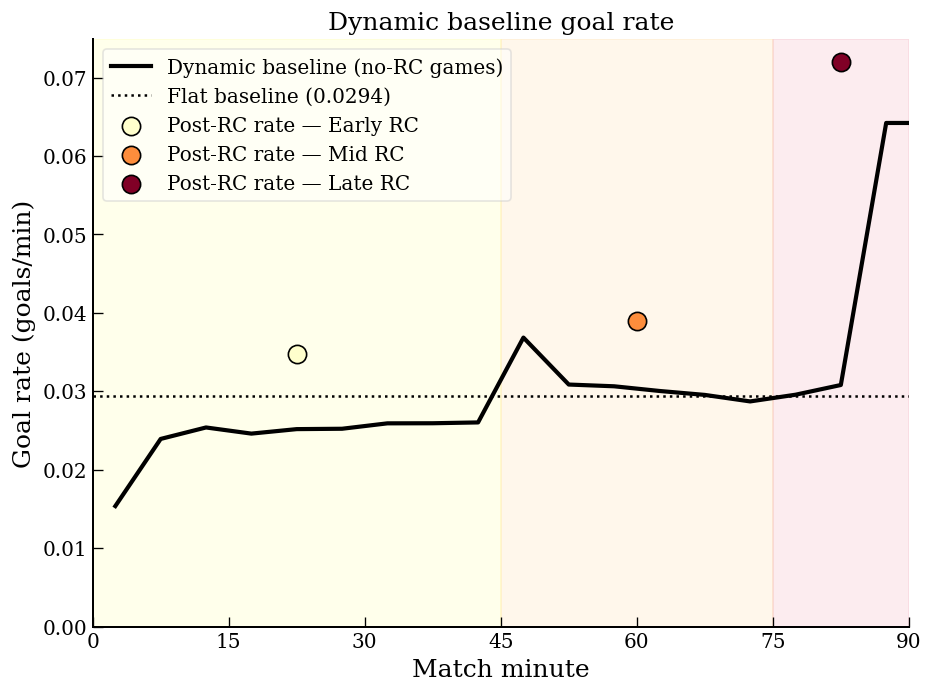

In [21]:
'''Plot dynamic baseline curve'''

fig, ax = plt.subplots(figsize=(8, 6))

# Add shaded phase regions with requested colors
for t0, t1, col, label in [
    (0, 45, 'yellow', 'Early (1–45)'),
    (45, 75, 'orange', 'Mid (46–75)'),
    (75, 90, 'crimson', 'Late (76–90)'),
]:
    ax.axvspan(t0, t1, alpha=0.08, color=col, label=None) # No label to avoid duplicate legend entries

# Baseline curve
ax.plot(baseline_curve.index + 2.5, baseline_curve.values,
        color='black', linewidth=2.5, label='Dynamic baseline (no-RC games)',
        linestyle='-')

# Add flat baseline
flat_rate = goals_no_rc['game_id'].count() / (n_no_rc_games * 90)
ax.axhline(
    flat_rate,
    color='black',
    linestyle=':',
    linewidth=1.5,
    label=f'Flat baseline ({flat_rate:.4f})'
)

# Post-RC rates per phase for comparison (from phase_df)
phase_bins  = {'Early': (0,45), 'Mid': (45,75), 'Late': (75,90)}
scatter_colors = plt.colormaps['YlOrRd'].resampled(len(phase_df))

for i, row in phase_df.iterrows():
    phase_label_full = row['phase']
    post_rate = row['obs_rate'] # Use the observed rate from phase_df

    phase_key = phase_label_full.split(' ')[0]
    t0, t1 = phase_bins.get(phase_key, (None, None))

    if t0 is not None and t1 is not None:
        midpoint = (t0 + t1) / 2
        ax.scatter(midpoint, post_rate, color=scatter_colors(i / (len(phase_df) - 1)),
                   s=120, zorder=4, edgecolor='black',
                   label=f'Post-RC rate — {phase_key} RC')

ax.set_xlabel('Match minute')
ax.set_xticks(np.arange(0, 91, 15)) # Set x-axis ticks
ax.set_xticklabels(['0', '15', '30', '45', '60', '75', '90'])
ax.set_ylabel('Goal rate (goals/min)')
ax.set_yticks(np.arange(0, 0.071, 0.01))
ax.set_title('Dynamic baseline goal rate')
ax.legend(frameon=True, framealpha=0.5)
ax.set_xlim(0, 90)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

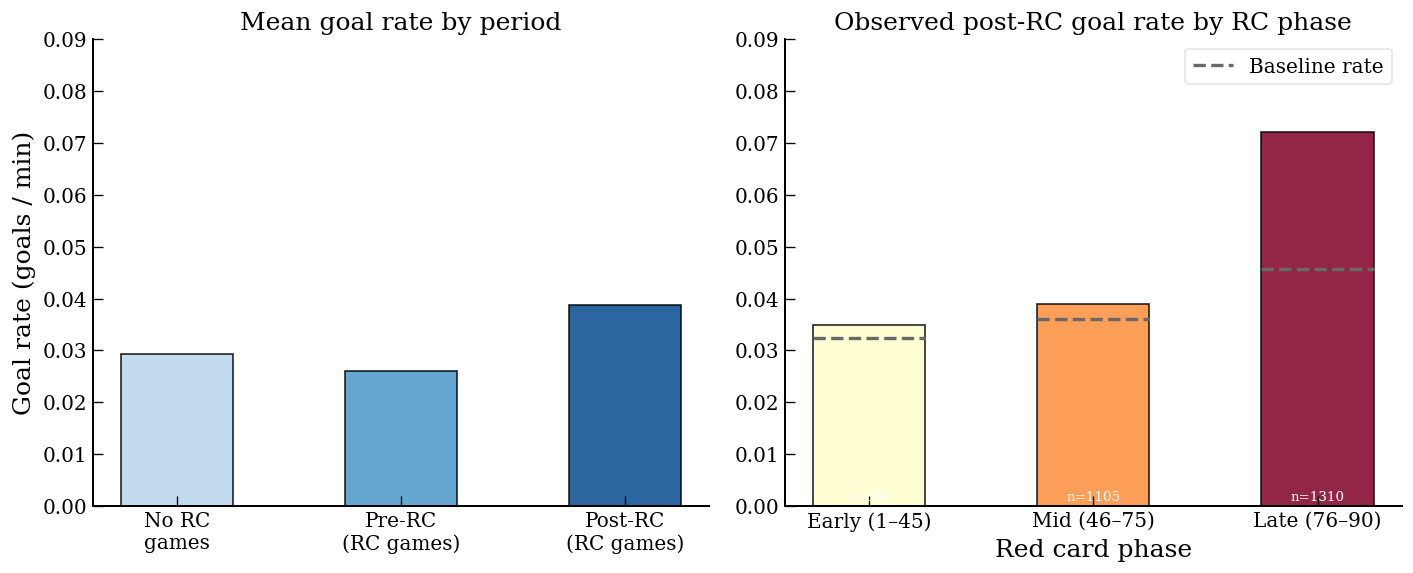

In [22]:
'''Goal rate visualisation - period and phase'''

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

t_cmap = plt.colormaps['YlOrRd'].resampled(len(phase_df))

# Left: aggregate goal rate by period
ax = axes[0]
period_order = ['no_rc', 'before_rc', 'after_rc']
period_label = {'no_rc': 'No RC\ngames', 'before_rc': 'Pre-RC\n(RC games)',
                'after_rc': 'Post-RC\n(RC games)'}
p_cmap_colors = [plt.colormaps['Blues'](0.3),
                 plt.colormaps['Blues'](0.6),
                 plt.colormaps['Blues'](0.9)]

for i, p in enumerate(period_order):
    ax.bar(i, agg_rates[p],
           color=p_cmap_colors[i], alpha=0.85, width=0.5, edgecolor='black')

ax.set_xticks(range(3))
ax.set_xticklabels([period_label[p] for p in period_order])
ax.set_ylabel('Goal rate (goals / min)')
ax.set_title('Mean goal rate by period')
ax.set_ylim(0, 0.09)
ax.set_yticks(np.arange(0, 0.091, 0.01))
nice_axes(ax)

# Right: observed post-RC rate vs baseline by phase
ax = axes[1]
x_pos = np.arange(len(phase_df))
bars  = ax.bar(x_pos, phase_df['obs_rate'],
               color=[t_cmap(i) for i in range(len(phase_df))],
               alpha=0.85, width=0.5, edgecolor='black')

for i, row in phase_df.iterrows():
    ax.hlines(row['exp_rate'], i - 0.25, i + 0.25,
              color='dimgrey', linestyle='--', linewidth=2,
              label='Baseline rate' if i == 0 else '')

for bar, row in zip(bars, phase_df.itertuples()):
    ax.text(bar.get_x() + bar.get_width() / 2, 0.0005,
            f'n={row.n}', ha='center', va='bottom',
            fontsize=8, color='white')

ax.set_xticks(x_pos)
ax.set_xticklabels(phase_df['phase'])
ax.set_xlabel('Red card phase')
ax.set_title('Observed post-RC goal rate by RC phase')
ax.legend(frameon=True, framealpha=0.5)
ax.set_ylim(0, 0.09)
ax.set_yticks(np.arange(0, 0.091, 0.01))
nice_axes(ax)
plt.tight_layout()
plt.show()

In [23]:
'''Rate ratio from dynamic expected curve integration'''

# Compute observed rates for the three existing bars
period_stats = {}
for p in ['no_rc', 'before_rc', 'after_rc']:
    sub  = periods[periods['period'] == p]['rate']
    mean = sub.mean()
    lo, hi = stats.t.interval(0.95, df=len(sub) - 1,
                               loc=mean, scale=stats.sem(sub))
    period_stats[p] = {'mean': mean, 'lo': lo, 'hi': hi}

# Compute the dynamically expected post-RC rate:
# For every RC game, integrate the baseline curve over its post-RC window, then divide total expected goals by total post-RC minutes
rc_games_all     = games[games['has_red_card'] == 1].dropna(subset=['first_rc_minute'])
total_exp_post   = sum(
    expected_goals_in_window(row.first_rc_minute, 90)
    for _, row in rc_games_all.iterrows()
)
total_post_min   = rc_games_all['minutes_after_rc'].clip(lower=1).sum()
exp_post_rc_rate = total_exp_post / total_post_min

# Also compute the observed post-RC rate on the same games for consistency
obs_post_rc_rate = (
    rc_games_all['total_goals_after_rc'].sum() / total_post_min
)
rate_ratio_descriptive = obs_post_rc_rate / exp_post_rc_rate
print(f"\nObserved post-RC rate: {obs_post_rc_rate:.5f} goals/min")
print(f"Dynamically expected rate: {exp_post_rc_rate:.5f} goals/min")
print(f"Rate ratio: {rate_ratio_descriptive:.4f}")


Observed post-RC rate: 0.03881 goals/min
Dynamically expected rate: 0.03456 goals/min
Rate ratio: 1.1230


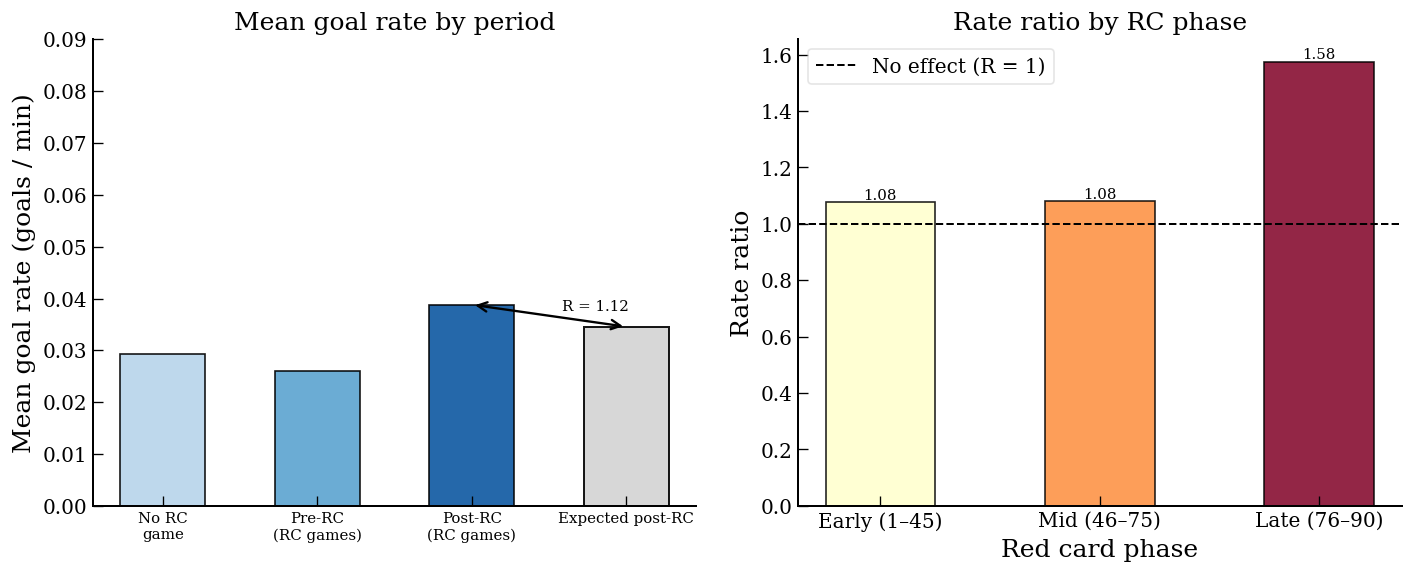

In [24]:
'''Update bar chart to show the expected vs observed post-RC goal rate'''

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

bar_labels = ['No RC\ngame', 'Pre-RC\n(RC games)',
              'Post-RC\n(RC games)', 'Expected post-RC']
bar_colors = [
    plt.colormaps['Blues'](0.30),
    plt.colormaps['Blues'](0.55),
    plt.colormaps['Blues'](0.85),
    'lightgrey',
]

obs_post_rc_rate   = agg_rates['after_rc']
rate_ratio_descriptive = obs_post_rc_rate / exp_post_rc_rate

# Left panel: barcharts
ax0 = axes[0]
for i, p in enumerate(['no_rc', 'before_rc', 'after_rc']):
    ax0.bar(i, agg_rates[p],
            color=bar_colors[i], alpha=0.9, width=0.55, edgecolor='black')

# Expected no-RC rate
ax0.bar(3, exp_post_rc_rate, color=bar_colors[3], alpha=0.9,
        width=0.55, edgecolor='black', linewidth=1.2,
        label='Dynamic baseline')

ax0.annotate('',
             xy=(2, obs_post_rc_rate), xytext=(3, exp_post_rc_rate),
             arrowprops=dict(arrowstyle='<->', color='black', lw=1.4))
ax0.text(2.8, (obs_post_rc_rate + exp_post_rc_rate) / 2 + 0.001,
        f'R = {rate_ratio_descriptive:.2f}',
        ha='center', fontsize=9, color='black')

ax0.set_xticks(range(4))
ax0.set_xticklabels(bar_labels, fontsize=9)
ax0.set_ylabel('Mean goal rate (goals / min)')
ax0.set_ylim(0, 0.09)
ax0.set_yticks(np.arange(0, 0.091, 0.01))
ax0.set_title('Mean goal rate by period')
nice_axes(ax0)

# Right panel: rate ratio by RC phase
ax1 = axes[1]
rr_cmap = plt.colormaps['YlOrRd'].resampled(len(phase_df))
x_pos   = np.arange(len(phase_df))
rr_bars = ax1.bar(x_pos, phase_df['rate_ratio'],
                  color=[rr_cmap(i) for i in range(len(phase_df))],
                  alpha=0.85, width=0.5, edgecolor='black')
ax1.axhline(1.0, color='black', linestyle='--', linewidth=1.2,
            label='No effect (R = 1)')

for bar, row in zip(rr_bars, phase_df.itertuples()):
    ax1.text(bar.get_x() + bar.get_width() / 2,
             row.rate_ratio + 0.01,
             f'{row.rate_ratio:.2f}',
             ha='center', fontsize=9)

ax1.set_xticks(x_pos)
ax1.set_xticklabels(phase_df['phase'])
ax1.set_xlabel('Red card phase')
ax1.set_ylabel('Rate ratio')
ax1.set_title('Rate ratio by RC phase')
ax1.legend(frameon=True, framealpha=0.5)
nice_axes(ax1)
plt.tight_layout()
plt.show()

In [25]:
'''Update RC side effect analysis considering rate ratio'''

#  Build side-specific baseline curves
BIN_WIDTH    = 5
all_bins     = pd.Index(range(0, 90, BIN_WIDTH), name='minute_bin')
no_rc_ids    = games[games['has_red_card'] == 0]['game_id']
goals_no_rc  = goals[goals['game_id'].isin(no_rc_ids)].copy()
n_no_rc      = len(no_rc_ids)

goals_no_rc['minute_bin'] = (
    (goals_no_rc['minute'] // BIN_WIDTH) * BIN_WIDTH
).clip(upper=85)

# Separate curves for home and away goals in no-RC games
for side in ['home', 'away']:
    side_curve = (
        goals_no_rc[goals_no_rc['side'] == side]
        .groupby('minute_bin').size()
        .reindex(all_bins, fill_value=0)
        .astype(float)
    )
    side_curve = (side_curve / (n_no_rc * BIN_WIDTH)
                  ).replace(0, np.nan).interpolate().fillna(method='bfill')
    if side == 'home':
        baseline_curve_home = side_curve
    else:
        baseline_curve_away = side_curve

print("Home baseline rate (goals/min):", baseline_curve_home.mean().round(5))
print("Away baseline rate (goals/min):", baseline_curve_away.mean().round(5))

# Dynamic expected post-RC rate per game per side
rc_games = games[games['has_red_card'] == 1].dropna(subset=['first_rc_minute']).copy()
rc_games = rc_games[rc_games['minutes_after_rc'] > 0].copy()

rc_games['exp_home_after'] = rc_games['first_rc_minute'].apply(
    lambda m: expected_goals_in_window(m, 90, baseline_curve_home)
)
rc_games['exp_away_after'] = rc_games['first_rc_minute'].apply(
    lambda m: expected_goals_in_window(m, 90, baseline_curve_away)
)

# Convert expected goals to expected rates
rc_games['exp_home_rate'] = (rc_games['exp_home_after'] /
                              rc_games['minutes_after_rc'].clip(lower=1))
rc_games['exp_away_rate'] = (rc_games['exp_away_after'] /
                              rc_games['minutes_after_rc'].clip(lower=1))

# Observed post-RC rates per game per side
rc_games['obs_home_rate'] = (rc_games['home_goals_after_rc'] /
                              rc_games['minutes_after_rc'].clip(lower=1))
rc_games['obs_away_rate'] = (rc_games['away_goals_after_rc'] /
                              rc_games['minutes_after_rc'].clip(lower=1))

# Rate ratios by RC side
print("\nDynamic rate ratios by RC side:")
print(f"{'RC side':<8} {'Obs home':>10} {'Exp home':>10} {'RR home':>10} "
      f"{'Obs away':>10} {'Exp away':>10} {'RR away':>10}")

for rc_side in ['home', 'away']:
    sub = rc_games[rc_games['rc_side'] == rc_side]
    obs_h = sub['obs_home_rate'].mean()
    exp_h = sub['exp_home_rate'].mean()
    obs_a = sub['obs_away_rate'].mean()
    exp_a = sub['exp_away_rate'].mean()
    print(f"{rc_side:<8} {obs_h:>10.5f} {exp_h:>10.5f} {obs_h/exp_h:>10.3f} "
          f"{obs_a:>10.5f} {exp_a:>10.5f} {obs_a/exp_a:>10.3f}")

# RC team = whichever side got the card
rc_games['obs_rc_team_rate']     = np.where(
    rc_games['rc_side'] == 'home',
    rc_games['obs_home_rate'], rc_games['obs_away_rate']
)
rc_games['obs_nonrc_team_rate']  = np.where(
    rc_games['rc_side'] == 'home',
    rc_games['obs_away_rate'], rc_games['obs_home_rate']
)
rc_games['exp_rc_team_rate']     = np.where(
    rc_games['rc_side'] == 'home',
    rc_games['exp_home_rate'], rc_games['exp_away_rate']
)
rc_games['exp_nonrc_team_rate']  = np.where(
    rc_games['rc_side'] == 'home',
    rc_games['exp_away_rate'], rc_games['exp_home_rate']
)

rr_rc_team    = (rc_games['obs_rc_team_rate'].mean() /
                 rc_games['exp_rc_team_rate'].mean())
rr_nonrc_team = (rc_games['obs_nonrc_team_rate'].mean() /
                 rc_games['exp_nonrc_team_rate'].mean())

print(f"\nRC team    post-RC rate ratio (obs/exp): {rr_rc_team:.3f}")
print(f"Non-RC team post-RC rate ratio (obs/exp): {rr_nonrc_team:.3f}")
print(f"Net combined rate ratio                 : {(rr_rc_team + rr_nonrc_team)/2:.3f}")

Home baseline rate (goals/min): 0.01615
Away baseline rate (goals/min): 0.01323

Dynamic rate ratios by RC side:
RC side    Obs home   Exp home    RR home   Obs away   Exp away    RR away
home        0.01359    0.02243      0.606    0.03582    0.01837      1.950
away        0.03777    0.02233      1.692    0.01045    0.01829      0.571

RC team    post-RC rate ratio (obs/exp): 0.634
Non-RC team post-RC rate ratio (obs/exp): 1.741
Net combined rate ratio                 : 1.188


In [26]:
'''Competition effect'''

# Per-competition mean goals summary
comp_summary = (
    games.groupby(['competition', 'has_red_card'])['total_goals']
    .mean().unstack('has_red_card')
    .rename(columns={0: 'No RC', 1: 'RC'})
)
comp_summary['difference'] = comp_summary['RC'] - comp_summary['No RC']
comp_summary['total_games'] = games.groupby('competition').size()
comp_summary['n_rc_games'] = (games[games.has_red_card==1]
                               .groupby('competition').size())

print(comp_summary.sort_values('difference', ascending=False).round(3).to_string())

has_red_card             No RC     RC  difference  total_games  n_rc_games
competition                                                               
Primera, Spain           2.478  2.663       0.185         1900         412
League One, England      2.612  2.742       0.130         2608         341
1. Bundesliga, Germany   3.128  3.250       0.122         1530         184
Championship, England    2.502  2.590       0.088         2759         317
League Two, England      2.433  2.516       0.083         2648         378
Premier League, England  2.776  2.828       0.052         1900         203
Ligue 2, France          2.295  2.340       0.045         1797         409
Ligue 1, France          2.693  2.730       0.037         1799         400
Serie A, Italy           2.836  2.863       0.027         1899         365
2. Bundesliga, Germany   2.951  2.841      -0.110         1530         264


In [27]:
# Per-competition rate summary
comp_baseline = (periods[periods['period'].isin(['no_rc','before_rc'])]
                 .groupby('competition')['rate'].mean()
                 .rename('baseline_rate'))
comp_postrc   = (periods[periods['period'] == 'after_rc']
                 .groupby('competition')['rate'].mean()
                 .rename('postrc_rate'))
comp_summary  = pd.concat([comp_baseline, comp_postrc], axis=1).dropna()

# Calculate the overall average dynamic baseline rate from the phase-specific rates
#overall_dynamic_baseline_rate = np.mean(list(dynamic_baseline_rates.values()))

# Recalculate rate_diff using the overall dynamic baseline rate
comp_summary['rate_diff'] = comp_summary['postrc_rate'] - comp_summary['baseline_rate'] #overall_dynamic_baseline_rate

comp_summary['n_rc'] = (games[games.has_red_card==1]
                        .groupby('competition').size())
print(comp_summary.sort_values('rate_diff', ascending=False).round(5).to_string())

                         baseline_rate  postrc_rate  rate_diff  n_rc
competition                                                         
Serie A, Italy                 0.03074      0.11246    0.08172   365
2. Bundesliga, Germany         0.03165      0.10461    0.07296   264
Championship, England          0.02733      0.07899    0.05165   317
1. Bundesliga, Germany         0.03413      0.08428    0.05015   184
Primera, Spain                 0.02717      0.07436    0.04719   412
League One, England            0.02869      0.07376    0.04507   341
League Two, England            0.02673      0.06904    0.04231   378
Ligue 1, France                0.02888      0.06787    0.03898   400
Premier League, England        0.03046      0.06690    0.03644   203
Ligue 2, France                0.02456      0.05827    0.03371   409


In [28]:
'''Per-competition rate ratios'''

comp_results = []
for comp in sorted(games['competition'].unique()):

    # Fit a competition-specific baseline curve
    comp_no_rc_ids = games[
        (games['competition'] == comp) &
        (games['has_red_card'] == 0)
    ]['game_id'].values
    n_comp_no_rc = len(comp_no_rc_ids)

    if n_comp_no_rc < 20:
        continue   # too few no-RC games for a stable curve

    goals_comp = goals[goals['game_id'].isin(comp_no_rc_ids)].copy()
    goals_comp['minute_bin'] = (
        (goals_comp['minute'] // BIN_WIDTH) * BIN_WIDTH
    ).clip(upper=85)

    comp_curve = (
        goals_comp.groupby('minute_bin').size()
        .reindex(all_bins, fill_value=0)
        .astype(float)
    )
    comp_curve = comp_curve / (n_comp_no_rc * BIN_WIDTH)
    comp_curve = comp_curve.replace(0, np.nan).interpolate().fillna(method='bfill')

    # RC games in this competition
    comp_rc_games = games[
        (games['competition'] == comp) &
        (games['has_red_card'] == 1)
    ].dropna(subset=['first_rc_minute'])

    if len(comp_rc_games) == 0:
        continue

    obs_post   = comp_rc_games['total_goals_after_rc'].sum()
    post_min   = comp_rc_games['minutes_after_rc'].clip(lower=1).sum()
    obs_pre    = comp_rc_games['total_goals_before_rc'].sum()
    pre_min    = comp_rc_games['minutes_before_rc'].clip(lower=1).sum()

    exp_post = sum(
        expected_goals_in_window(row.first_rc_minute, 90, comp_curve)
        for _, row in comp_rc_games.iterrows()
    )
    exp_pre  = sum(
        expected_goals_in_window(0, row.first_rc_minute, comp_curve)
        for _, row in comp_rc_games.iterrows()
    )

    obs_post_rate = obs_post / post_min
    exp_post_rate = exp_post / post_min
    obs_pre_rate  = obs_pre  / pre_min
    exp_pre_rate  = exp_pre  / pre_min

    comp_results.append({
        'competition'        : comp,
        'obs_post_rate'      : obs_post_rate,
        'exp_post_rate'      : exp_post_rate,
        'post_rate_ratio'    : obs_post_rate / exp_post_rate if exp_post_rate > 0 else np.nan,
        'obs_pre_rate'       : obs_pre_rate,
        'exp_pre_rate'       : exp_pre_rate,
        'pre_rate_ratio'     : obs_pre_rate  / exp_pre_rate  if exp_pre_rate  > 0 else np.nan,
        'n_rc_games'         : len(comp_rc_games),
        'n_no_rc_games'      : n_comp_no_rc,
    })

comp_rr_df = (pd.DataFrame(comp_results)
                .sort_values('post_rate_ratio', ascending=False))
print("\nPer-competition rate ratios:")
print(comp_rr_df[['competition','post_rate_ratio','pre_rate_ratio',
                   'n_rc_games','n_no_rc_games']].round(4).to_string(index=False))


Per-competition rate ratios:
            competition  post_rate_ratio  pre_rate_ratio  n_rc_games  n_no_rc_games
         Primera, Spain           1.2116          1.0205         412           1488
    League One, England           1.1908          0.9737         341           2267
 1. Bundesliga, Germany           1.1750          0.9599         184           1346
  Championship, England           1.1464          0.9735         317           2442
Premier League, England           1.1334          0.9437         203           1697
         Serie A, Italy           1.1298          0.9594         365           1534
        Ligue 2, France           1.1207          0.9557         409           1388
    League Two, England           1.0844          1.0056         378           2270
        Ligue 1, France           1.0804          0.9695         400           1399
 2. Bundesliga, Germany           1.0615          0.9093         264           1266


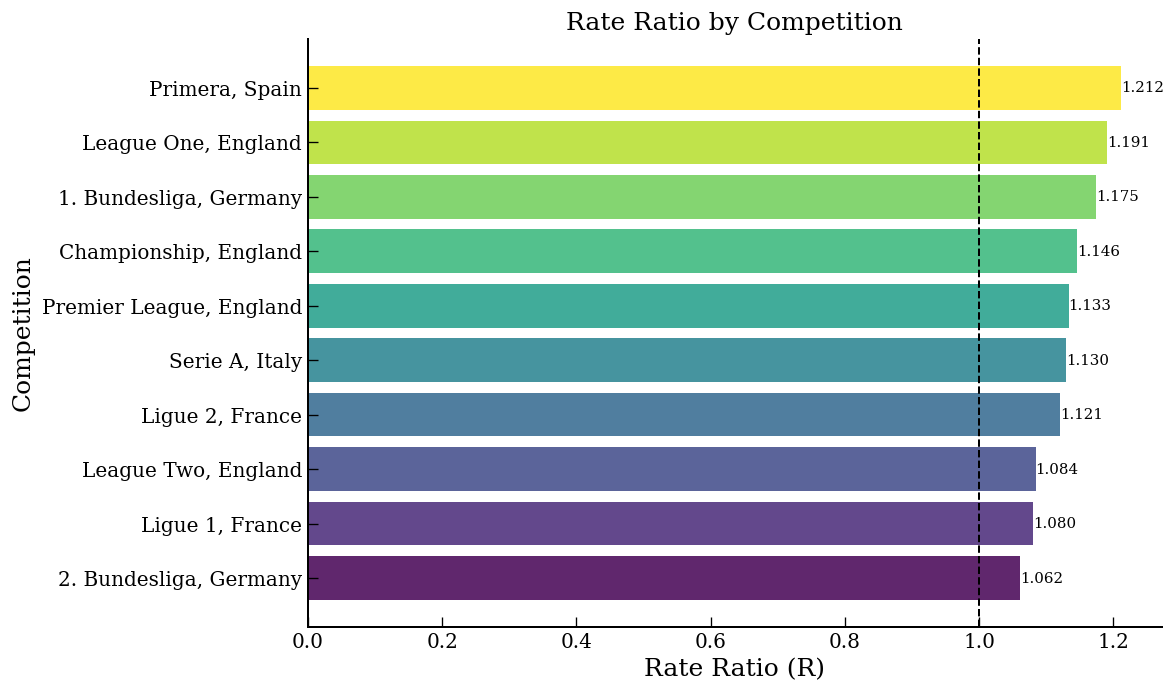

In [29]:
'''Plot per-comp ratios'''

fig, ax = plt.subplots(figsize=(10, 6))

comp_sorted = comp_rr_df.sort_values('post_rate_ratio', ascending=True)
c_cmap = plt.colormaps['viridis'].resampled(len(comp_sorted))

# Set up positions for bars
index = np.arange(len(comp_sorted))

bars1 = ax.barh(index, comp_sorted['post_rate_ratio'], label='Post-RC Rate Ratio',
                color=[c_cmap(i) for i in range(len(comp_sorted))], alpha=0.85)

# Add numerical labels to the end of each bar
for bar in bars1:
    width = bar.get_width()
    ax.text(width, bar.get_y() + bar.get_height()/2, f'{width:.3f}',
            ha='left', va='center', fontsize=9)

ax.axvline(1.0, color='black', linewidth=1.2, linestyle='--', label='No effect (R = 1)')
ax.set_xlabel('Rate Ratio (R)')
ax.set_ylabel('Competition')
ax.set_title('Rate Ratio by Competition')
ax.set_yticks(index)
ax.set_yticklabels(comp_sorted['competition'])
#ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
nice_axes(ax)
plt.tight_layout()
plt.show()

In [32]:
'''Poisson GLM Model'''

# Prepare glm_data
glm_data = periods[periods['minutes'] > 0].copy()

# Compute dynamic expected goals and log offset on glm_data
glm_data['expected_goals_dynamic'] = glm_data.apply(
    lambda row: expected_goals_in_window(*get_window(row)), axis=1
)
glm_data['log_expected_dynamic'] = np.log(
    glm_data['expected_goals_dynamic'].clip(lower=1e-6)
)

# Sanity check — expected vs actual goals per period
sanity = glm_data.groupby('period')[['goals', 'expected_goals_dynamic']].mean().round(4)
sanity['ratio (obs/exp)'] = (sanity['goals'] / sanity['expected_goals_dynamic']).round(4)
sanity['difference']      = (sanity['goals'] - sanity['expected_goals_dynamic']).round(4)
print("Expected vs observed goals (sanity check):")
print(sanity)

print(f"Post-RC Ratio = {sanity['ratio (obs/exp)']['after_rc']:.4f} i.e. expect around 8% increase.")

Expected vs observed goals (sanity check):
            goals  expected_goals_dynamic  ratio (obs/exp)  difference
period                                                                
after_rc   1.2066                  1.1146           1.0825      0.0920
before_rc  1.6508                  1.7140           0.9631     -0.0632
no_rc      2.6437                  2.6437           1.0000      0.0000
Post-RC Ratio = 1.0825 i.e. expect around 8% increase.


In [31]:
'''Poisson GLM Models'''

# Prepare glm data
glm_data = periods[periods['minutes'] > 0].copy()

glm_data['expected_goals_dynamic'] = glm_data.apply(
    lambda row: expected_goals_in_window(*get_window(row)), axis=1
)
glm_data['log_expected_dynamic'] = np.log(
    glm_data['expected_goals_dynamic'].clip(lower=1e-6)
)

# sanity check to see what value to expect
sanity = glm_data.groupby('period')[['goals', 'expected_goals_dynamic']].mean().round(4)
sanity['ratio (obs/exp)'] = (sanity['goals'] / sanity['expected_goals_dynamic']).round(4)
sanity['difference']      = (sanity['goals'] - sanity['expected_goals_dynamic']).round(4)
print("Expected vs observed goals (sanity check):")
print(sanity)
print()

Expected vs observed goals (sanity check):
            goals  expected_goals_dynamic  ratio (obs/exp)  difference
period                                                                
after_rc   1.2066                  1.1146           1.0825      0.0920
before_rc  1.6508                  1.7140           0.9631     -0.0632
no_rc      2.6437                  2.6437           1.0000      0.0000



In [33]:
'''Calculate scoreline at RC time for game state covariate'''

# Compute scoreline at RC minute
rc_games_sc = games[games['has_red_card'] == 1].dropna(subset=['first_rc_minute'])

scorelines = []
for _, g in rc_games_sc.iterrows():
    game_goals = goals[goals['game_id'] == g.game_id]
    home_at_rc = (game_goals[
        (game_goals['side'] == 'home') &
        (game_goals['minute'] < g.first_rc_minute)
    ]).shape[0]
    away_at_rc = (game_goals[
        (game_goals['side'] == 'away') &
        (game_goals['minute'] < g.first_rc_minute)
    ]).shape[0]
    goal_diff  = home_at_rc - away_at_rc

    if   g.rc_side == 'home': rc_team_diff = goal_diff
    elif g.rc_side == 'away': rc_team_diff = -goal_diff
    else:                     rc_team_diff = 0

    if   rc_team_diff > 0:  status = 'winning'
    elif rc_team_diff == 0: status = 'drawing'
    else:                   status = 'losing'

    scorelines.append({
        'game_id'         : g.game_id,
        'goal_diff_at_rc' : goal_diff,
        'rc_team_diff'    : rc_team_diff,
        'rc_team_status'  : status,
    })

scoreline_df = pd.DataFrame(scorelines)
print("RC team status at time of card:")
print(scoreline_df['rc_team_status'].value_counts())
print()

# Merge scoreline at RC minute into glm_data
glm_data = glm_data.merge(
    scoreline_df[['game_id', 'goal_diff_at_rc', 'rc_team_diff', 'rc_team_status']],
    on='game_id', how='left'
)
glm_data['rc_team_status']   = glm_data['rc_team_status'].fillna('no_rc')
glm_data['rc_min_filled']    = glm_data['first_rc_min'].fillna(0)
glm_data['has_rc_min']       = glm_data['first_rc_min'].notna().astype(int)
glm_data['goal_diff_filled'] = glm_data['goal_diff_at_rc'].fillna(0)

# S3 base dataset — expected_goals_dynamic > 0
glm_data_s3 = glm_data[glm_data['expected_goals_dynamic'] > 0].copy()

print(f"glm_data_s3 rows : {len(glm_data_s3):,}")
print()

RC team status at time of card:
rc_team_status
drawing    1392
losing     1197
winning     684
Name: count, dtype: int64

glm_data_s3 rows : 23,100



In [36]:
'''Fit GLM models'''

# S1: flat offset, competition only
poisson_s1 = smf.glm(
    'goals ~ is_after_rc + C(competition)',
    data   = glm_data_s3,
    family = sm.families.Poisson(),
    offset = glm_data_s3['log_minutes']
).fit()
print("S1  fitted.")

# S2: dynamic offset, competition only
poisson_s2 = smf.glm(
    'goals ~ is_after_rc + C(competition)',
    data   = glm_data_s3,
    family = sm.families.Poisson(),
    offset = glm_data_s3['log_expected_dynamic']
).fit()
print("S2 fitted.")

# S3: dynamic offset, all
poisson_s3 = smf.glm(
    'goals ~ is_after_rc + C(rc_side) + C(rc_team_status) '
    '+ rc_min_filled + has_rc_min + C(competition)',
    data   = glm_data_s3,
    family = sm.families.Poisson(),
    offset = glm_data_s3['log_expected_dynamic']
).fit()
print("S3 fitted.")

# Extract ratios and statistics
def extract_rr(model, label):
    coef = model.params['is_after_rc']
    ci   = model.conf_int().loc['is_after_rc']
    pval = model.pvalues['is_after_rc']
    return {
        'Model'      : label,
        'Coef (log)' : round(coef, 4),
        'R'          : round(np.exp(coef), 4),
        'CI low'     : round(np.exp(ci[0]), 4),
        'CI high'    : round(np.exp(ci[1]), 4),
        'p-value'    : round(pval, 4),
        'AIC'        : round(model.aic, 2),
        'Sig'        : 'Yes' if pval < 0.05 else 'No',}

all_models = {
    'S1  — flat offset'                  : poisson_s1,
    'S2 — dynamic offset'               : poisson_s2,
    'S3 — dynamic + all covariates'     : poisson_s3}

results_df = pd.DataFrame([extract_rr(m, l) for l, m in all_models.items()])
print()
print(results_df.to_string(index=False))

S1  fitted.
S2 fitted.
S3 fitted.

                        Model  Coef (log)      R  CI low  CI high  p-value      AIC Sig
            S1  — flat offset      0.2695 1.3093  1.2638   1.3563   0.0000 80783.70 Yes
          S2 — dynamic offset      0.0908 1.0951  1.0570   1.1344   0.0000 80649.63 Yes
S3 — dynamic + all covariates      0.0836 1.0872  1.0308   1.1465   0.0021 80470.58 Yes
